In [1]:
import sys
print(sys.executable)

import torch
print(torch.__version__)

d:\learning\AI\LLM\runnoob_ai\.venv\Scripts\python.exe
2.14.1+cpu


In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
def f(x):
    return 3*x**2-4*x+5

f(3.0)

20.0

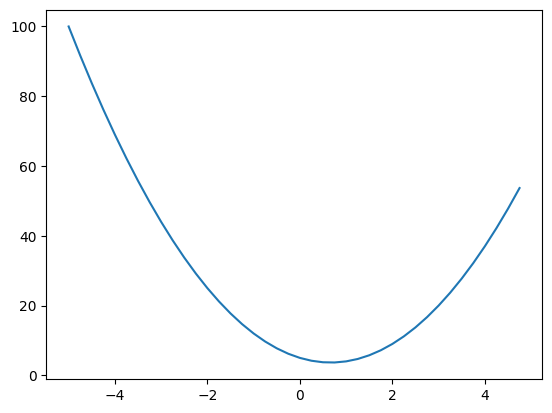

In [4]:
xs=np.arange(-5,5,0.25)
ys=f(xs)
plt.plot(xs,ys)

In [5]:
h=0.000001
x=-3.0
f(x)
f(x+h)
(f(x+h)-f(x))/h

-21.999997002808414

In [6]:
a=2.0
b=-3.0
c=10.0
d=a*b+c
print(d)

4.0


In [7]:
h=0.0001
a=2.0
b=-3.0
c=10.0
d1=a*b+c
c+=h
d2=a*b+c
print('d1',d1)
print('d2',d2)
print('derivative/slope',(d2-d1)/h)

d1 4.0
d2 4.0001
derivative/slope 0.9999999999976694


h=0.0001
a=2.0
b=-3.0
c=10.0
d1=a*b+c
a+=h
d2=a*b+c
print('d1',d1)
print('d2',d2)
print('derivative/slope',(d2-d1)/h)

In [ ]:
class Value:
    def __init__(self,data, _children=(), _op='',label=''):
        self.data=data
        self.grad=0.0 #初始化梯度为0，假设其不影响变量的改变
        
        self._prev=set(_children)
        self._op=_op
        self.label=label

    def __repr__(self): 
        return f"Value(data={self.data})"  #打印

    def __add__(self,other):
        out=Value(self.data+other.data, (self,other), '+')
        return out
    def __mul__(self,other):
        out=Value(self.data*other.data, (self,other), '*')
        return out
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t, (self,), 'tanh')
        return out

    
a=Value(2.0, label='a')
b=Value(-3.0, label='b')
c=Value(10.0, label='c')
e=a*b; e.label='e'
d=e+c; d.label='d'
f=Value(-2.0, label='f')
L=d*f; L.label='L'


In [18]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [21]:
import os
import subprocess

graphviz_bin = r"C:\Program Files\Graphviz\bin"
os.environ["PATH"] = graphviz_bin + os.pathsep + os.environ.get("PATH", "")

subprocess.run(["dot", "-V"], check=True)

CompletedProcess(args=['dot', '-V'], returncode=0)

In [22]:
from graphviz import Digraph

def trace(root):
    #builds a set of all nodes and edges in a graph
    nodes,edges = set(),set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
        for child in v._prev:
            edges.add((child, v))
            build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR-left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label=f"{n.label} | data={n.data:.4f} | grad={n.grad:.4f}", shape="record")
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
    # and connect this node to it
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

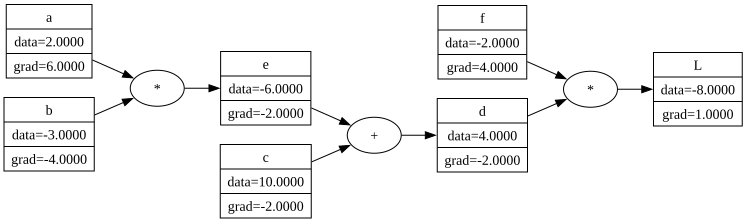

In [37]:
draw_dot(L)

L=d*f
dL/dd =? f

In [29]:
L.grad=1.0
f.grad=4.0
d.grad=-2.0

dL/dc?

first
dd/dc

d=c+e
dd/dc=1.0
dd/de=1.0

链式法则
Want:
dL/dc=(dL/dd)*(dd/dc)

Know:
dL/dd
dd/dc

In [35]:
c.grad=-2.0
e.grad=-2.0

dL/de=-2.0

dL/da=(dL/de)*(de/da)
dL/db

In [36]:
a.grad=-2.0*-3.0
b.grad=-2.0*2.0

In [ ]:
#让他们沿着自己的梯度往上走（无所谓本身的值是正的还是负的）
#这就是一个优化的步骤，grad教我们这些值是如何影响最终结果的
a.data += 0.01*a.grad
b.data += 0.01*b.grad
c.data += 0.01*c.grad
f.data += 0.01*f.grad

e=a*b
d=e+c
L=d*f

print(L.data)

-7.286496


In [39]:
def lol():
    h=0.001

    a=Value(2.0, label='a')
    b=Value(-3.0, label='b')
    c=Value(10.0, label='c')
    e=a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f; L.label='L'
    L1=L.data

    a=Value(2.0, label='a')
    b=Value(-3.0+h, label='b')
    c=Value(10.0+h, label='c')
    e=a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f; L.label='L'
    L2=L.data

    print((L2-L1)/h)
lol()

-5.999999999998451


neural network

In [ ]:
x1=Value(2.0,label='x1')
x2=Value(0.0,label='x2')

w1=Value(-3.0,label='w1')
w2=Value(1.0,label='w2')

b=Value(6.8813735870195432,label='b')

x1w1 = x1*w1;x1w1.label= 'x1*w1'
x2w2 = x2*w2;x2w2.label='x2*w2'
x1w1x2w2 = x1w1 + x2w2;x1w1x2w2.label='x1*w1+x2*w2'
n = x1w1x2w2+b;n.label='n'

o=n.tanh();o.label='o'

draw_dot(o)

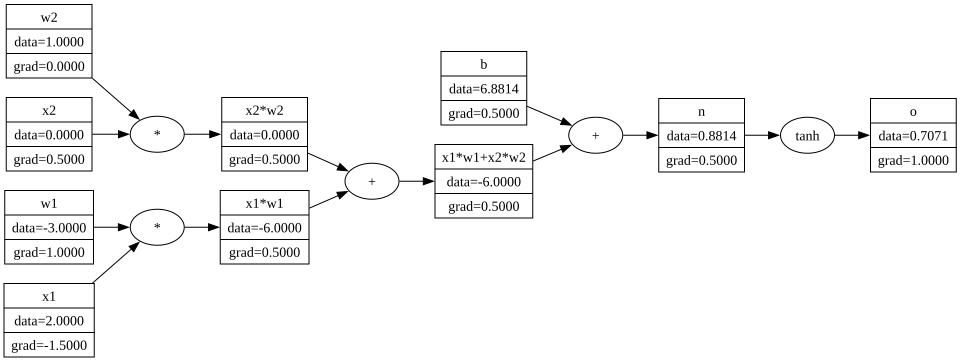

In [56]:
draw_dot(o)

In [ ]:
o.grad=1.0

In [48]:
n.grad=1.0-o.data**2

In [50]:
x1w1x2w2.grad=n.grad
b.grad=n.grad

In [51]:
x1w1.grad=x1w1x2w2.grad
x2w2.grad=x1w1x2w2.grad

In [53]:
x2.grad=x2w2.grad*w2.data
w2.grad=x2w2.grad*x2.data

In [55]:
x1.grad=x1w1.grad*w1.data
w1.grad=x1w1.grad*x1.data

In [ ]:
#o=tanh(n)
#do/dn=1-tanh^2(n)
#do/dn=1-o^2